In [1]:
import gym, os
from itertools import count
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.distributions import Categorical
import matplotlib.pyplot as plt
from torchsummary import summary

import numpy as np
import pandas as pd 

import torch.optim as optim
import random
import numpy as np
from collections import deque
from data_extract_45_updated import process_topology

import os
import gc

In [2]:
def find_json_file(directory):
    # Search for the first JSON file in the specified directory
    for filename in os.listdir(directory):
        if filename.endswith('.json'):
            return os.path.join(directory, filename)  # Return the full path of the first found JSON file
    return None   

In [3]:
json_directory = os.getcwd()
json_file_path = find_json_file(json_directory)
num_functions = 4  

cloud_node, regional_nodes, edge_nodes, latency = process_topology(json_file_path)

fixed_costs = np.array([5, 10, 20])

#cost for XP and ET>> CN, RN , EN            
variable_costs1 = np.array([[4,8,16],
                  [1,2,4]])

#cost for SD and DB>> CN, RN, EN 
variable_costs2 = np.array([[2,4,8],
                  [2,4,8]])

# all_coordinates = generate_coordinates()

In [4]:
print(regional_nodes)
print(edge_nodes)

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
[12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44]


In [5]:
def encode_node_types(cloud_nodes, regional_nodes, edge_nodes):
    node_type_list = []

    # Assign type encodings
    for node in cloud_nodes:
        node_type_list.append([node, 0])  # Cloud → 0
    for node in regional_nodes:
        node_type_list.append([node, 1])  # Regional → 1
    for node in edge_nodes:
        node_type_list.append([node, 2])  # Edge → 2

    # Convert to NumPy array and sort by node ID
    node_type_array = np.array(node_type_list)
    node_type_array = node_type_array[node_type_array[:, 0].argsort()]

    return node_type_array

node_encoded= encode_node_types(cloud_node, regional_nodes, edge_nodes)

print(node_encoded)

[[ 0  0]
 [ 1  1]
 [ 2  1]
 [ 3  1]
 [ 4  1]
 [ 5  1]
 [ 6  1]
 [ 7  1]
 [ 8  1]
 [ 9  1]
 [10  1]
 [11  1]
 [12  2]
 [13  2]
 [14  2]
 [15  2]
 [16  2]
 [17  2]
 [18  2]
 [19  2]
 [20  2]
 [21  2]
 [22  2]
 [23  2]
 [24  2]
 [25  2]
 [26  2]
 [27  2]
 [28  2]
 [29  2]
 [30  2]
 [31  2]
 [32  2]
 [33  2]
 [34  2]
 [35  2]
 [36  2]
 [37  2]
 [38  2]
 [39  2]
 [40  2]
 [41  2]
 [42  2]
 [43  2]
 [44  2]]


In [6]:
def compute_cost_new(action, previous_action, variable_costs):
    node_class = int(node_encoded[node_encoded[:, 0] == action, 1][0])

    # Waive the fixed cost only when this exact node has already been activated.
    if action in previous_action:
        total_cost = 0
    else:
        total_cost = fixed_costs[node_class]

    for j in range(variable_costs.shape[0]):
        total_cost += variable_costs[j, node_class]

    return total_cost



In [7]:
# Concatenate b as the first column of a
# state= np.concatenate((latency, node_cost1, node_cost2), axis=1)
state=latency.copy()
print(state.shape)

(45, 45)


In [8]:
#state

In [9]:
#k=0
#state[k,:] #represent k'th node latencys with all other nodes 

In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
lr = 0.000001
gamma=0.99
random_seed= 543

In [11]:
LARGE_VALUE = 20
LATENCY_LIMIT_MS = 10.0

# ============================================================
# V8 COST-AWARE REWARD SCALING
# ============================================================
#
# Agent 1 new-node costs by node class:
#   fixed_cost + XP cost + E2T cost
#
# Agent 2 new-node costs by node class:
#   fixed_cost + SDL cost + DB cost
#
# These scales are used only to normalize the action cost into
# approximately [0, 1].  The actual episode cost accumulated in
# all_cost1/all_cost2 remains unchanged.
# ============================================================

AGENT1_MAX_ACTION_COST = float(
    np.max(
        fixed_costs
        + np.sum(variable_costs1, axis=0)
    )
)

AGENT2_MAX_ACTION_COST = float(
    np.max(
        fixed_costs
        + np.sum(variable_costs2, axis=0)
    )
)


def _repeat_penalty(
    action,
    previous_action,
    base_penalty=1,
    growth_factor=5,
    max_penalty=1000.0
):
    """
    Retained for reference/backward compatibility.

    V8 valid-action masking prevents zero-coverage/repeated-useless
    actions, so this penalty is not used in the V8 reward.
    """
    penalty = 0.0
    repeat_count = 0

    for prev in reversed(previous_action):
        if prev == action:
            penalty += base_penalty * (
                growth_factor ** repeat_count
            )
            repeat_count += 1

            if penalty >= max_penalty:
                return max_penalty
        else:
            break

    return min(penalty, max_penalty)


# ============================================================
# AGENT 1 REWARD - V8
# ============================================================
#
# IMPORTANT DIFFERENCES FROM V7:
#
# 1) Coverage/latency are evaluated ONLY on the actual Agent-1
#    target columns (edge_nodes), not on every column of the
#    full latency matrix.
#
# 2) The extremely small reciprocal cost term:
#
#       omega1 / c_total
#
#    is replaced by a normalized linear cost penalty:
#
#       - omega_cost * (c_total / AGENT1_MAX_ACTION_COST)
#
#    This makes the cost signal comparable in magnitude with
#    coverage and latency.
#
# 3) Because valid-action masking guarantees N_covered > 0,
#    P_no_coverage and P_repeat are not needed.
#
# Reward:
#
#   R1 =
#       omega_coverage * N_covered
#       - omega_cost * normalized_cost
#       - omega_latency * normalized_mean_latency
#
# ============================================================

def compute_reward1(
    state,
    action,
    cost_action,
    previous_action,
    variable_cost,
    target_nodes,
    omega_coverage=5.0,
    omega_cost=5.0,
    omega_latency=2.0
):
    action = int(action)
    target_nodes = np.asarray(target_nodes, dtype=int)

    c_total = compute_cost_new(
        action,
        cost_action,
        variable_cost
    )

    # Only currently relevant Agent-1 target columns.
    target_latencies = state[
        action,
        target_nodes
    ]

    covered_latencies = target_latencies[
        target_latencies <= LATENCY_LIMIT_MS
    ]

    N_covered = int(
        covered_latencies.size
    )

    normalized_cost = (
        float(c_total)
        / max(AGENT1_MAX_ACTION_COST, 1e-8)
    )

    if N_covered > 0:
        mean_latency = float(
            np.mean(covered_latencies)
        )

        normalized_latency = (
            mean_latency
            / LATENCY_LIMIT_MS
        )
    else:
        # Should not occur under valid-action masking.
        mean_latency = LATENCY_LIMIT_MS
        normalized_latency = 1.0

    reward = (
        omega_coverage * N_covered
        - omega_cost * normalized_cost
        - omega_latency * normalized_latency
    )

    return (
        c_total,
        float(reward),
        N_covered,
        target_latencies
    )


# ============================================================
# AGENT 2 REWARD - V8
# ============================================================
#
# Agent 2's state already represents the full-loop condition.
# Therefore V8 keeps Agent 2 focused on:
#
#   - covering feasible Agent-1 anchors
#   - minimizing placement cost
#
# No additional latency-minimization term is added here.
# ============================================================

def compute_reward2(
    state,
    action,
    cost_action,
    previous_action,
    variable_cost,
    target_nodes,
    omega_coverage=5.0,
    omega_cost=5.0
):
    action = int(action)
    target_nodes = np.asarray(target_nodes, dtype=int)

    c_total = compute_cost_new(
        action,
        cost_action,
        variable_cost
    )

    total_loop_latencies = state[
        action,
        target_nodes
    ]

    N_covered = int(
        np.sum(
            total_loop_latencies
            <= LATENCY_LIMIT_MS
        )
    )

    normalized_cost = (
        float(c_total)
        / max(AGENT2_MAX_ACTION_COST, 1e-8)
    )

    reward = (
        omega_coverage * N_covered
        - omega_cost * normalized_cost
    )

    return (
        c_total,
        float(reward),
        N_covered,
        total_loop_latencies
    )


In [12]:
state.shape[0]//8

5

In [13]:
class Actor(nn.Module):
    def __init__(self, state_size, action_size):
        super(Actor, self).__init__()
        self.action_size = action_size
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, stride=1, padding=1)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2) 

        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2) 

        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2) 
        # self.conv4 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)

        
        # Calculate the flattened size after convolutions
        #self._to_linear = 64 * state_size[0] // 8 * state_size[1] // 8  # Adjust based on input dimensions
        
        self.fc1 = nn.Linear(64*(state.shape[0]//8)*(state.shape[0]//8), 1024)
        self.fc2 = nn.Linear(1024, 512)
        # self.fc3 = nn.Linear(self._to_linear, 512)
        self.fc4 = nn.Linear(512, action_size)



    def forward(self, x):
        # Add a channel dimension to 2D input (batch_size, 1, height, width)
        x = x.unsqueeze(1)  # Ensure the input is (batch_size, 1, height, width)
        
        # Apply convolutional layers with ReLU activation
        x = F.relu(self.conv1(x))
        x = self.pool1(x)
        
        x = F.relu(self.conv2(x))
        x = self.pool2(x)
        
        x = F.relu(self.conv3(x))
        x = self.pool3(x)
        
        # Flatten the output from convolutional layers
        x = x.view(x.size(0), -1)  # Flatten all dimensions except batch
        
        # # Fully connected layers
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc4(x)

        # V7 numerical-stability change:
        # Pass raw network outputs as logits. Categorical performs the
        # normalization internally using a numerically stable log-sum-exp.
        x = Categorical(logits=x)
        
        return x



if __name__ == '__main__':
    actor = Actor([state.shape[0], state.shape[1]], state.shape[0])
    input_shape = state.shape # (channels, height, width)
    summary(actor, input_shape, device='cpu')

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 16, 45, 45]             160
         MaxPool2d-2           [-1, 16, 22, 22]               0
            Conv2d-3           [-1, 32, 22, 22]           4,640
         MaxPool2d-4           [-1, 32, 11, 11]               0
            Conv2d-5           [-1, 64, 11, 11]          18,496
         MaxPool2d-6             [-1, 64, 5, 5]               0
            Linear-7                 [-1, 1024]       1,639,424
            Linear-8                  [-1, 512]         524,800
            Linear-9                   [-1, 45]          23,085
Total params: 2,210,605
Trainable params: 2,210,605
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 0.54
Params size (MB): 8.43
Estimated Total Size (MB): 8.98
---------------------------------------

In [14]:
class Critic(nn.Module):
    def __init__(self, state_size):
        super(Critic, self).__init__()

        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, stride=1, padding=1)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2) 

        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2) 

        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2) 
        # self.conv4 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)

        
        # Calculate the flattened size after convolutions
        self._to_linear = 64 * state_size[0] // 8 * state_size[1] // 8  # Adjust based on input dimensions
        
        self.fc1 = nn.Linear(64*(state.shape[0]//8)*(state.shape[0]//8), 512)
        self.fc2 = nn.Linear(512, 256)
        # self.fc3 = nn.Linear(self._to_linear, 512)
        self.fc4 = nn.Linear(256, 1)


    def forward(self, x):
        # Add a channel dimension to 2D input (batch_size, 1, height, width)
        x = x.unsqueeze(1)  # Ensure the input is (batch_size, 1, height, width)
        
        # Apply convolutional layers with ReLU activation
        x = F.relu(self.conv1(x))
        x = self.pool1(x)
        
        x = F.relu(self.conv2(x))
        x = self.pool2(x)
        
        x = F.relu(self.conv3(x))
        x = self.pool3(x)
        
        # Flatten the output from convolutional layers
        x = x.view(x.size(0), -1)  # Flatten all dimensions except batch
        
        # Fully connected layers
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc4(x)


        
        return x
    

if __name__ == '__main__':
    actor = Critic([state.shape[0], state.shape[0]])
    input_shape = state.shape  # (channels, height, width)
    summary(actor, input_shape, device='cpu')

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 16, 45, 45]             160
         MaxPool2d-2           [-1, 16, 22, 22]               0
            Conv2d-3           [-1, 32, 22, 22]           4,640
         MaxPool2d-4           [-1, 32, 11, 11]               0
            Conv2d-5           [-1, 64, 11, 11]          18,496
         MaxPool2d-6             [-1, 64, 5, 5]               0
            Linear-7                  [-1, 512]         819,712
            Linear-8                  [-1, 256]         131,328
            Linear-9                    [-1, 1]             257
Total params: 974,593
Trainable params: 974,593
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 0.53
Params size (MB): 3.72
Estimated Total Size (MB): 4.26
-------------------------------------------

In [15]:
# state1=state[:, edge_nodes+[-2]]
def compute_returns(next_value, rewards, masks, gamma=0.99):
    R = next_value
    returns = []
    for step in reversed(range(len(rewards))):
        R = rewards[step] + gamma * R * masks[step]
        returns.insert(0, R)
    return returns


def update_state(state, action):
    updated_state = np.copy(state)
    latency_idx=np.where(updated_state[action, :] <= 10)[0]
    updated_state[:, latency_idx] = LARGE_VALUE  # Mark selected node's latencies as high
    return updated_state

# state1.shape

In [16]:
# V7 - Numerically stable valid-action-masked stochastic A2C
state_size=[state.shape[0], state.shape[0]]
action_size=state.shape[0]

actor1 = Actor(state_size, action_size).to(device)
critic1 = Critic(state_size).to(device)

optimizerA1 = optim.Adam(actor1.parameters(), lr=0.000001)
optimizerC1 = optim.Adam(critic1.parameters(), lr=0.000001)

avg_return1=[]
avg_a_loss1=[]
avg_c_loss1=[]

TOTAL_EPISODES = 2500

actor2 = Actor(state_size, action_size).to(device)
critic2 = Critic(state_size).to(device)

optimizerA2 = optim.Adam(actor2.parameters(), lr=0.000001)
optimizerC2 = optim.Adam(critic2.parameters(), lr=0.000001)

avg_return2=[]
avg_a_loss2=[]
avg_c_loss2=[]
all_cost1=[]
all_cost2=[]


In [17]:
state1=state.copy() #Create a mask for columns that are NOT in edge_nodes

# print(state1)

mask = np.ones(state1.shape[1], dtype=bool)
# print(mask)
mask[edge_nodes] = False  # Set False for columns in edge_nodes
# print(mask)


# Apply LARGE_VALUE to all columns except edge_nodes
state1[:, mask] = LARGE_VALUE

print(state1)


[[20 20 20 ... 10 10 12]
 [20 20 20 ... 18 18 32]
 [20 20 20 ... 20  8 22]
 ...
 [20 20 20 ...  0 20 22]
 [20 20 20 ... 20  0 22]
 [20 20 20 ... 22 22  0]]


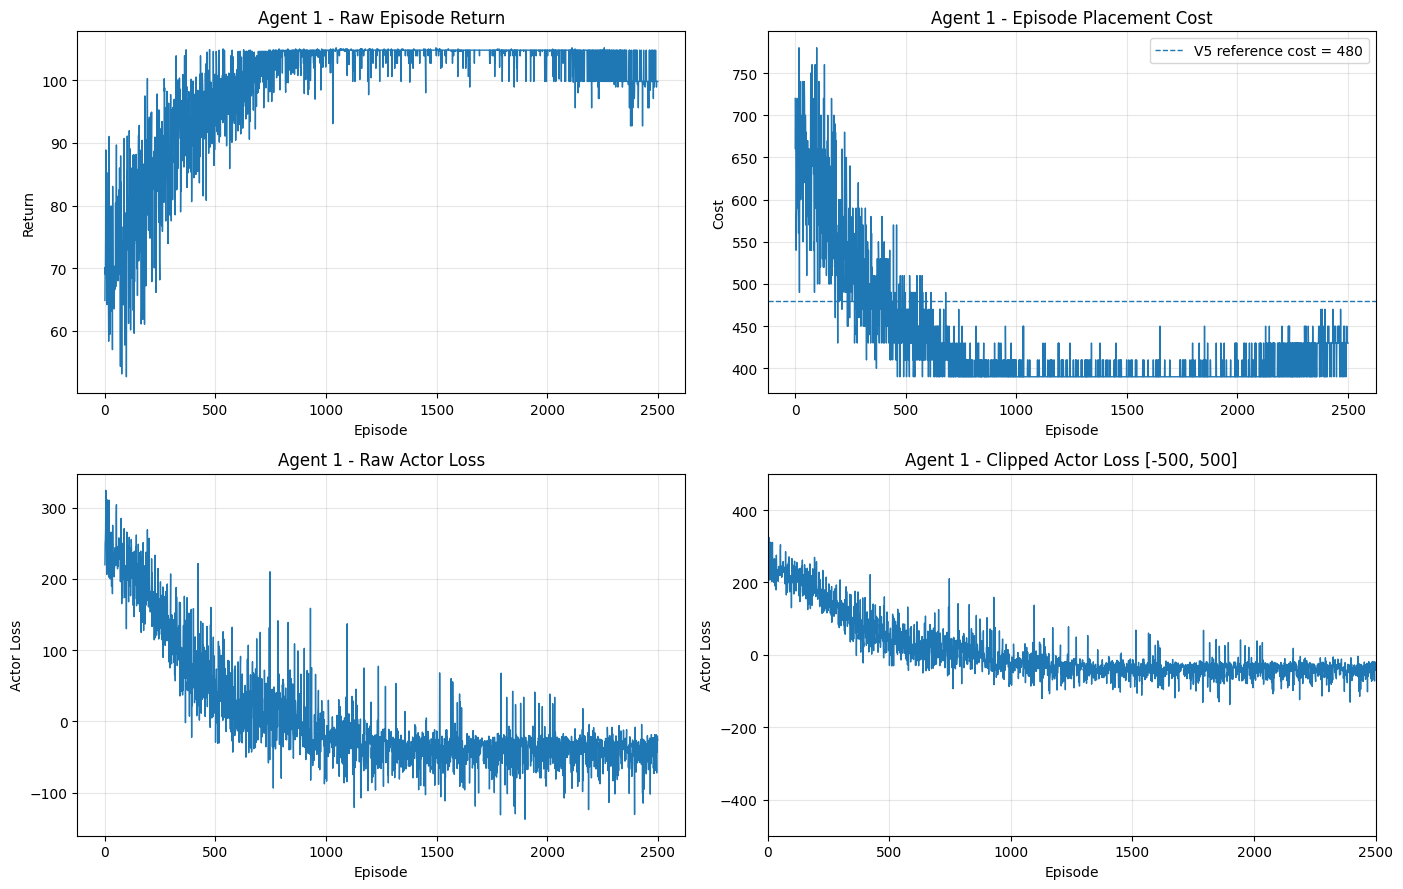

Episode 1 starts
Episode 1: Agent 1 Actor Loss: 219.8425, Agent 1 Critic Loss: 1495.3303, Return: 64.8343, Cost: 720.00, Steps: 20, Nodes: [5, 34, 7, 36, 20, 1, 21, 24, 31, 32, 33, 8, 18, 23, 41, 44, 40, 35, 28, 13]
Episode 2 starts
Episode 2: Agent 1 Actor Loss: 249.9298, Agent 1 Critic Loss: 1381.4404, Return: 70.1000, Cost: 660.00, Steps: 18, Nodes: [12, 2, 36, 19, 14, 17, 23, 32, 8, 13, 22, 10, 35, 29, 24, 41, 33, 28]
Episode 3 starts
Episode 3: Agent 1 Actor Loss: 254.5656, Agent 1 Critic Loss: 890.5953, Return: 69.0133, Cost: 700.00, Steps: 20, Nodes: [14, 4, 36, 22, 3, 37, 21, 26, 2, 8, 13, 6, 41, 35, 33, 44, 34, 40, 24, 28]
Episode 4 starts
Episode 4: Agent 1 Actor Loss: 268.5613, Agent 1 Critic Loss: 1504.2072, Return: 75.1643, Cost: 650.00, Steps: 19, Nodes: [7, 0, 6, 34, 31, 26, 24, 22, 35, 11, 4, 28, 44, 40, 33, 20, 37, 13, 41]
Episode 5 starts
Episode 5: Agent 1 Actor Loss: 324.5051, Agent 1 Critic Loss: 2469.8559, Return: 88.8867, Cost: 540.00, Steps: 16, Nodes: [24, 11, 

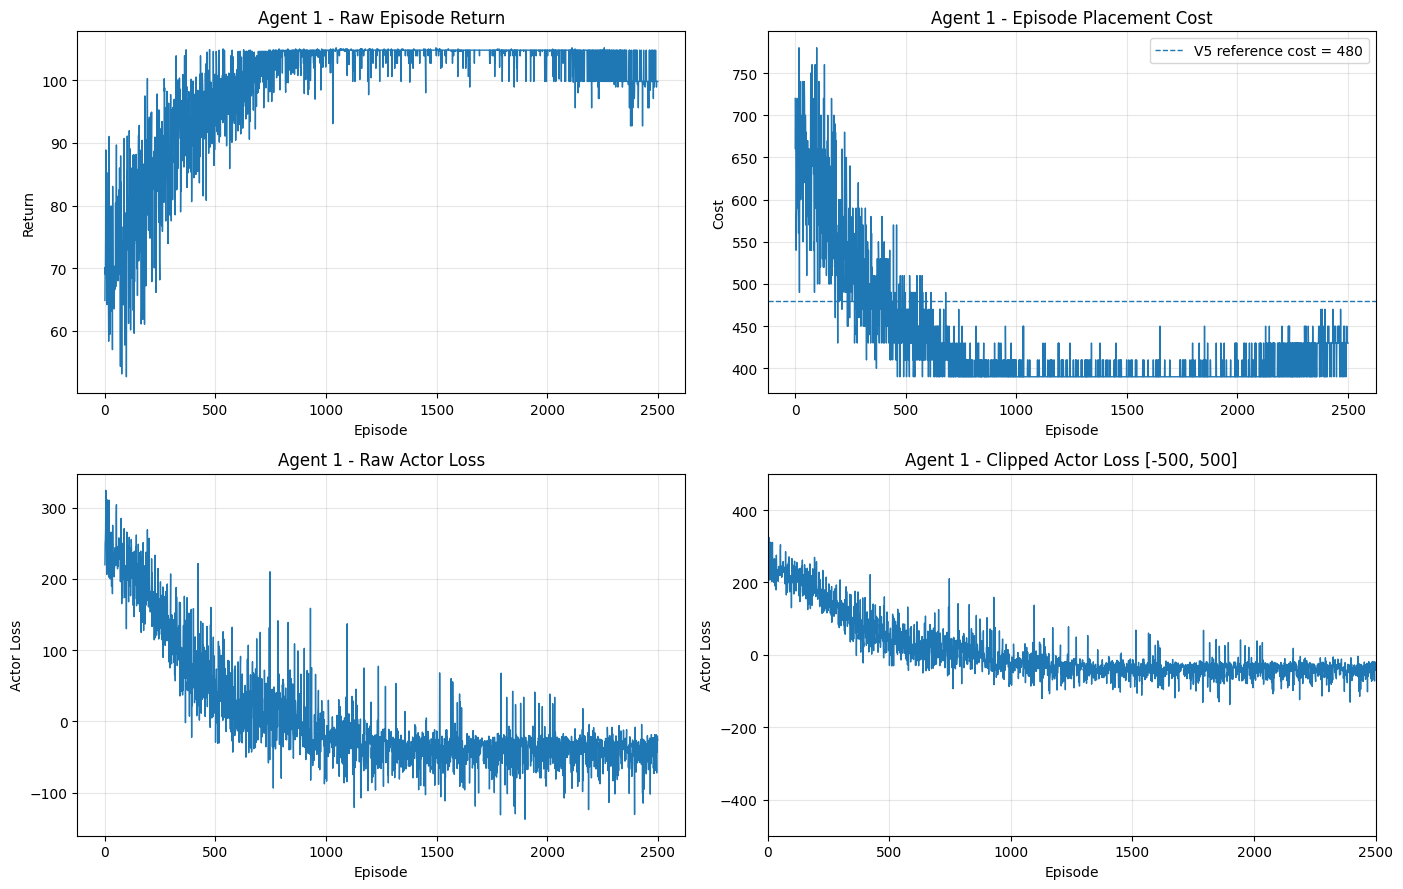

In [18]:
# ============================================================
# V8 - Agent 1: LOGIT-MASKED A2C + COST-AWARE NORMALIZED REWARD
#
# Why this version:
#   update_state() marks every E2 node covered by a selected node
#   as LARGE_VALUE for all candidate placement nodes.
#
#   Therefore, after a node is selected, selecting the same node
#   again cannot cover any currently-uncovered E2 node.
#
#   In the original unmasked training, the policy can nevertheless
#   sample such actions. Because _repeat_penalty() grows rapidly,
#   a short run of repeated selections can create a very large
#   negative episode return.
#
# V7 numerical-stability correction:
#   Keep the same valid-action masking, but apply the mask in
#   LOGIT space instead of multiplying probabilities and dividing
#   by their remaining probability mass.
#
# Why:
#   Near convergence, the actor can put almost all probability on
#   one preferred action. Later in the same episode that action can
#   become invalid. The old expression
#
#       masked_probs = probs * mask
#       masked_probs = masked_probs / masked_probs.sum()
#
#   can then divide by an extremely small number and create very
#   large/unstable gradients. Eventually actor parameters can become
#   NaN, which is what the reported Categorical(probs=...) error shows.
#
# V7 instead uses:
#
#       masked_logits = logits.masked_fill(~mask, -inf)
#       masked_dist = Categorical(logits=masked_logits)
#
#   This represents the same conditional policy over valid actions,
#   but avoids explicit tiny-probability renormalization.
#
# IMPORTANT:
#   - Still stochastic sampling.
#   - No deterministic argmax phase.
#   - No post-3600 special behavior.
#   - No Huber loss.
#   - No gradient clipping.
#   - MSE critic loss remains.
#   - Per-step A2C updates remain unchanged.
# ============================================================

import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from torch.distributions import Categorical


# ============================================================
# LIVE PLOT INITIALIZATION
# ============================================================

plt.ion()

fig_live, axes_live = plt.subplots(
    2,
    2,
    figsize=(14, 9)
)

line_return_raw, = axes_live[0, 0].plot([], [], linewidth=1)
axes_live[0, 0].set_title("Agent 1 - Raw Episode Return")
axes_live[0, 0].set_xlabel("Episode")
axes_live[0, 0].set_ylabel("Return")
axes_live[0, 0].grid(True, alpha=0.3)

line_cost, = axes_live[0, 1].plot([], [], linewidth=1)
axes_live[0, 1].set_title(
    "Agent 1 - Episode Placement Cost"
)
axes_live[0, 1].set_xlabel("Episode")
axes_live[0, 1].set_ylabel("Cost")
axes_live[0, 1].grid(True, alpha=0.3)

# Reference from the user's V5 experiment.
axes_live[0, 1].axhline(
    480,
    linestyle="--",
    linewidth=1,
    label="V5 reference cost = 480"
)
axes_live[0, 1].legend()

line_actor_raw, = axes_live[1, 0].plot([], [], linewidth=1)
axes_live[1, 0].set_title("Agent 1 - Raw Actor Loss")
axes_live[1, 0].set_xlabel("Episode")
axes_live[1, 0].set_ylabel("Actor Loss")
axes_live[1, 0].grid(True, alpha=0.3)

line_actor_clipped, = axes_live[1, 1].plot([], [], linewidth=1)
axes_live[1, 1].set_title(
    "Agent 1 - Clipped Actor Loss [-500, 500]"
)
axes_live[1, 1].set_xlabel("Episode")
axes_live[1, 1].set_ylabel("Actor Loss")
axes_live[1, 1].set_ylim(-500, 500)
axes_live[1, 1].grid(True, alpha=0.3)

plt.tight_layout()

display_handle = display(
    fig_live,
    display_id=True
)


# ============================================================
# TRAINING TIMER
# ============================================================

agent1_training_start = time.perf_counter()


# ============================================================
# AGENT 1 TRAINING
# ============================================================

for iter in range(1, TOTAL_EPISODES + 1):

    state_n1 = state1.copy()

    log_probs = []
    values = []
    rewards = []
    masks = []

    selected_nodes1 = []

    episode_reward = 0.0
    epsidoe_c_loss = 0.0
    episode_a_loss = 0.0

    previous_action = []
    episode_cost = 0.0

    advantages = []
    a_loss = []
    c_loss = []
    dists = []

    print(f"Episode {iter} starts")


    # ========================================================
    # PER-STEP A2C TRAINING
    # ========================================================

    for i in range(200):

        state_tensor = (
            torch.FloatTensor(state_n1)
            .unsqueeze(0)
            .to(device)
        )

        base_dist = actor1(state_tensor)
        value = critic1(state_tensor)


        # ====================================================
        # VALID-ACTION MASK
        # ====================================================
        #
        # Valid = this placement node can cover at least one
        # currently-uncovered E2 node with latency <= 10 ms.
        #
        # This automatically excludes previously selected nodes,
        # because their previously-covered E2 columns were already
        # changed to LARGE_VALUE by update_state().
        # ====================================================

        valid_action_mask_np = np.any(
            state_n1[:, edge_nodes] <= 10.0,
            axis=1
        )

        valid_action_mask = torch.as_tensor(
            valid_action_mask_np,
            dtype=torch.bool,
            device=device
        )

        if not torch.any(valid_action_mask):
            # No valid placement remains.
            # This should normally correspond to completion.
            break


        # ====================================================
        # V7 NUMERICALLY STABLE LOGIT MASKING
        # ====================================================
        #
        # base_dist was constructed with Categorical(logits=...).
        # Its .logits are normalized log-probabilities. Masking them
        # and passing them again as logits is equivalent to
        # conditioning the policy on the valid action set.
        #
        # Crucially, this avoids:
        #
        #     probs * mask
        #     / tiny_remaining_probability_mass
        #
        # which can become numerically unstable near convergence.
        # ====================================================

        base_logits = base_dist.logits.squeeze(0)

        if not torch.isfinite(base_logits).all():
            raise RuntimeError(
                f"Non-finite Agent 1 logits BEFORE masking at "
                f"episode={iter}, step={i}. "
                f"This means the actor parameters became non-finite "
                f"during an earlier optimizer update."
            )

        # Use a very negative finite value instead of explicit -inf.
        # This gives invalid actions effectively zero probability.
        mask_value = torch.finfo(base_logits.dtype).min

        masked_logits = base_logits.masked_fill(
            ~valid_action_mask,
            mask_value
        )

        # Still stochastic sampling -- NOT argmax.
        masked_dist = Categorical(
            logits=masked_logits
        )

        action = masked_dist.sample()

        action_id = int(action.item())

        selected_nodes1.append(
            action_id
        )


        # ----------------------------------------------------
        # Environment transition
        # ----------------------------------------------------

        next_state = update_state(
            state_n1,
            action_id
        )

        cost_action = previous_action

        cost, reward, n_cov, lat = compute_reward1(
            state_n1,
            action_id,
            cost_action,
            previous_action,
            variable_costs1,
            edge_nodes
        )


        # Safety check:
        # A masked action should ALWAYS cover something.
        if n_cov <= 0:
            raise RuntimeError(
                f"Masked Agent 1 selected a zero-coverage action: "
                f"episode={iter}, step={i}, action={action_id}"
            )


        done = np.all(
            next_state[:, edge_nodes]
            == LARGE_VALUE
        )


        previous_action.append(
            action_id
        )


        # ----------------------------------------------------
        # Next-state value
        # ----------------------------------------------------

        next_state_tensor = (
            torch.FloatTensor(next_state)
            .unsqueeze(0)
            .to(device)
        )

        next_value = critic1(
            next_state_tensor
        )


        # ----------------------------------------------------
        # One-step TD target / advantage
        # ----------------------------------------------------

        td_target = (
            reward
            + gamma
            * next_value
            * (1 - done)
        )

        advantage = (
            td_target - value
        )


        # ====================================================
        # CRITIC UPDATE - MSE
        # ====================================================

        critic_loss = F.mse_loss(
            value,
            td_target.detach()
        )

        if not torch.isfinite(critic_loss):
            raise RuntimeError(
                f"Non-finite Agent 1 critic loss at "
                f"episode={iter}, step={i}; "
                f"reward={reward}, value={value.item()}, "
                f"td_target={td_target.item()}."
            )

        epsidoe_c_loss += (
            critic_loss.item()
        )

        optimizerC1.zero_grad()

        critic_loss.backward()

        optimizerC1.step()


        # ====================================================
        # ACTOR UPDATE
        # ====================================================
        #
        # IMPORTANT:
        # log_prob MUST come from masked_dist because masked_dist
        # is the actual behavior policy that sampled this action.
        # ====================================================

        log_prob = masked_dist.log_prob(
            action
        )

        actor_loss = (
            -log_prob
            * advantage.detach()
        )

        if not torch.isfinite(actor_loss):
            raise RuntimeError(
                f"Non-finite Agent 1 actor loss at "
                f"episode={iter}, step={i}; "
                f"advantage={advantage.item()}, "
                f"log_prob={log_prob.item()}."
            )

        episode_a_loss += (
            actor_loss.item()
        )

        optimizerA1.zero_grad()

        actor_loss.backward()

        optimizerA1.step()


        # ====================================================
        # LOGGING
        # ====================================================

        log_probs.append(
            log_prob.item()
        )

        values.append(
            value.item()
        )

        rewards.append(
            reward
        )

        advantages.append(
            advantage.item()
        )

        a_loss.append(
            actor_loss.item()
        )

        c_loss.append(
            critic_loss.item()
        )

        episode_reward += reward
        episode_cost += cost

        state_n1 = next_state.copy()


        if done:
            break


    # ========================================================
    # END OF EPISODE
    # ========================================================

    avg_return1.append(
        episode_reward
    )

    avg_a_loss1.append(
        episode_a_loss
    )

    avg_c_loss1.append(
        epsidoe_c_loss
    )

    all_cost1.append(
        episode_cost
    )


    # ========================================================
    # LIVE TRAINING PLOT
    # ========================================================

    LIVE_PLOT_EVERY = 10

    if iter % LIVE_PLOT_EVERY == 0 or iter == 1:

        episodes = np.arange(
            1,
            len(avg_return1) + 1
        )

        raw_return = np.asarray(
            avg_return1,
            dtype=float
        )

        episode_cost_history = np.asarray(
            all_cost1,
            dtype=float
        )

        line_return_raw.set_data(
            episodes,
            raw_return
        )

        line_cost.set_data(
            episodes,
            episode_cost_history
        )


        raw_actor_loss = np.asarray(
            avg_a_loss1,
            dtype=float
        )

        clipped_actor_loss = np.clip(
            raw_actor_loss,
            -500,
            500
        )

        line_actor_raw.set_data(
            episodes,
            raw_actor_loss
        )

        line_actor_clipped.set_data(
            episodes,
            clipped_actor_loss
        )


        axes_live[0, 0].relim()
        axes_live[0, 0].autoscale_view()

        axes_live[1, 0].relim()
        axes_live[1, 0].autoscale_view()


        # Episode-cost plot: automatically rescale both axes.
        axes_live[0, 1].relim()
        axes_live[0, 1].autoscale_view()

        axes_live[1, 1].set_xlim(
            0,
            max(10, len(avg_a_loss1))
        )
        axes_live[1, 1].set_ylim(
            -500,
            500
        )


        fig_live.canvas.draw()
        fig_live.canvas.flush_events()

        display_handle.update(
            fig_live
        )


    # ========================================================
    # PRINT EVERY EPISODE
    # ========================================================

    print(
        f"Episode {iter}: "
        f"Agent 1 Actor Loss: {avg_a_loss1[-1]:.4f}, "
        f"Agent 1 Critic Loss: {avg_c_loss1[-1]:.4f}, "
        f"Return: {avg_return1[-1]:.4f}, "
        f"Cost: {all_cost1[-1]:.2f}, "
        f"Steps: {i + 1}, "
        f"Nodes: {selected_nodes1}"
    )


# ============================================================
# END TRAINING
# ============================================================

agent1_training_end = time.perf_counter()

agent1_training_time = (
    agent1_training_end
    - agent1_training_start
)

print(
    f"\nAgent 1 Training Time: "
    f"{int(agent1_training_time // 3600):02d}:"
    f"{int((agent1_training_time % 3600) // 60):02d}:"
    f"{agent1_training_time % 60:05.2f}"
)

display_handle.update(
    fig_live
)

plt.ioff()


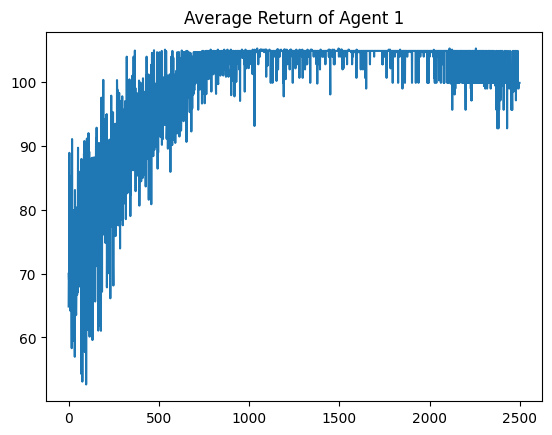

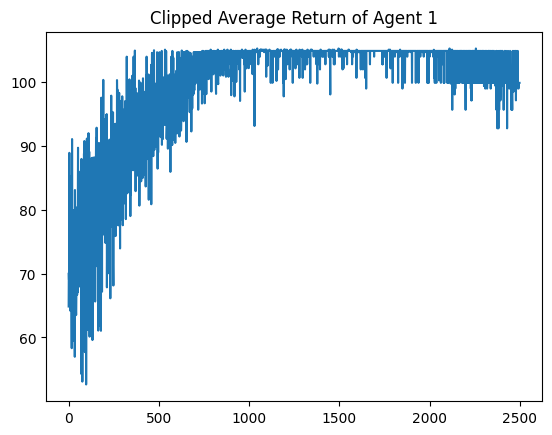

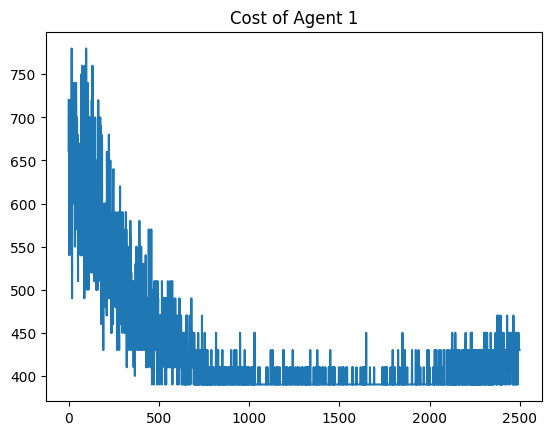

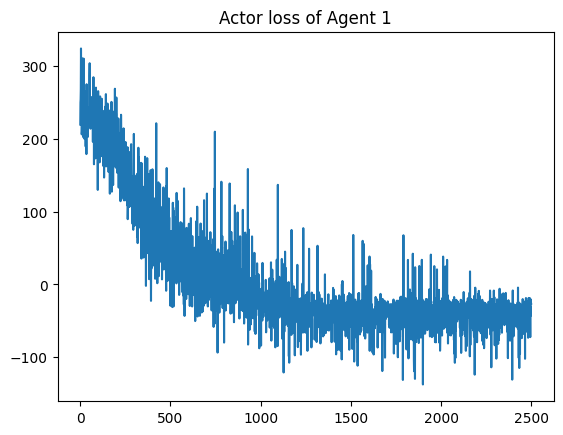

In [19]:
import matplotlib.pyplot as plt
plt.plot(avg_return1)
plt.title("Average Return of Agent 1")
plt.show()

# Define a clipping range
clipped_data1 = np.clip(avg_return1, -500, 500)

# Plot clipped data
plt.plot(clipped_data1)
plt.title("Clipped Average Return of Agent 1")
plt.show()

plt.plot(all_cost1)
plt.title("Cost of Agent 1")
plt.show()

plt.plot(avg_a_loss1)
plt.title("Actor loss of Agent 1")
plt.show()

In [20]:
print(np.unique(selected_nodes1))

[ 0  1  3  4  6  8 10 11 13 24 28 33 35 37 41]


In [21]:
# ============================================================
# BLOCK 1: Use <= 10 ms as the valid end-to-end latency limit
# ============================================================
LATENCY_THRESHOLD_MS = 10.0


# ============================================================
# BLOCK 2: Keep the unique G1 nodes learned by Agent 1
# ============================================================
selected_nodes1 = np.unique(
    np.asarray(selected_nodes1, dtype=int)
)


# ============================================================
# BLOCK 3: For each E2 node, select the learned G1 node having
# the lowest E2N-to-G1 latency and store that latency
# ============================================================
e2_to_g1 = {}
agent1_selected_latency = {}

for e2_node in edge_nodes:

    selected_g1 = min(
        selected_nodes1,
        key=lambda g1_node: latency[int(g1_node), int(e2_node)]
    )

    first_stage_latency = float(
        latency[int(selected_g1), int(e2_node)]
    )

    # A first-stage latency equal to 10 ms is valid.
    # Agent 2 must then select a G2 node having 0 ms latency
    # from this G1 node so that the total remains <= 10 ms.
    if first_stage_latency > LATENCY_THRESHOLD_MS:
        raise RuntimeError(
            f"Agent 1 did not learn a feasible G1 location for "
            f"E2 node {e2_node}. Lowest learned latency is "
            f"{first_stage_latency:.3f} ms."
        )

    e2_to_g1[int(e2_node)] = int(selected_g1)
    agent1_selected_latency[int(e2_node)] = first_stage_latency


# ============================================================
# BLOCK 4: Group the E2 nodes associated with each selected G1
# ============================================================
g1_to_e2 = {}

for e2_node, g1_node in e2_to_g1.items():
    g1_to_e2.setdefault(g1_node, []).append(e2_node)

active_g1_nodes = np.array(
    sorted(g1_to_e2.keys()),
    dtype=int
)


# ============================================================
# BLOCK 5: Store the worst E2N-to-G1 latency associated with
# each active G1 node
# ============================================================
g1_first_stage_latency = {
    g1_node: max(
        agent1_selected_latency[e2_node]
        for e2_node in assigned_e2_nodes
    )
    for g1_node, assigned_e2_nodes in g1_to_e2.items()
}


# ============================================================
# BLOCK 6: Display Agent 1 placement and stored latency results
# ============================================================
print("Agent 1 learned nodes:", selected_nodes1)
print("Active G1 nodes:", active_g1_nodes)
print("E2-to-G1 association:", e2_to_g1)
print(
    "Stored E2-to-G1 latencies (ms):",
    agent1_selected_latency
)
print(
    "Worst first-stage latency per G1 (ms):",
    g1_first_stage_latency
)


# ============================================================
# BLOCK 7: Build Agent 2 state using complete loop latency:
#
# E2N-to-G1 latency + G1-to-candidate-G2 latency
# Rows represent candidate G2 placement nodes.
# Columns represent G1 nodes selected by Agent 1.
#
# If the first-stage latency is 10 ms, only a candidate G2
# having 0 ms G1-to-G2 latency will satisfy <= 10 ms.
# ============================================================
state2 = np.full_like(
    state,
    LARGE_VALUE,
    dtype=float
)

for g1_node in active_g1_nodes:

    first_stage_latency = g1_first_stage_latency[g1_node]

    state2[:, g1_node] = (
        latency[:, g1_node] + first_stage_latency
    )


# ============================================================
# BLOCK 8: Verify that every active G1 has at least one
# candidate G2 node satisfying total latency <= 10 ms
# ============================================================
for g1_node in active_g1_nodes:

    feasible_g2_nodes = np.where(
        state2[:, g1_node] <= LATENCY_THRESHOLD_MS
    )[0]

    if feasible_g2_nodes.size == 0:
        raise RuntimeError(
            f"No feasible G2 location exists for G1 node "
            f"{g1_node} under the <= 10 ms total-latency limit."
        )

    print(
        f"G1 node {g1_node}: feasible G2 nodes = "
        f"{feasible_g2_nodes.tolist()}, total latencies = "
        f"{state2[feasible_g2_nodes, g1_node].tolist()}"
    )


# ============================================================
# BLOCK 9: Display the Agent 2 state
# ============================================================
state2

Agent 1 learned nodes: [ 0  1  3  4  6  8 10 11 13 24 28 33 35 37 41]
Active G1 nodes: [ 0  1  3  4  6  8 10 11 13 24 28 33 35 37 41]
E2-to-G1 association: {12: 8, 13: 13, 14: 10, 15: 11, 16: 6, 17: 11, 18: 11, 19: 1, 20: 8, 21: 11, 22: 1, 23: 6, 24: 24, 25: 11, 26: 11, 27: 8, 28: 28, 29: 3, 30: 1, 31: 3, 32: 4, 33: 33, 34: 10, 35: 35, 36: 0, 37: 37, 38: 1, 39: 11, 40: 10, 41: 41, 42: 0, 43: 0, 44: 10}
Stored E2-to-G1 latencies (ms): {12: 6.0, 13: 0.0, 14: 10.0, 15: 2.0, 16: 6.0, 17: 2.0, 18: 4.0, 19: 4.0, 20: 10.0, 21: 8.0, 22: 2.0, 23: 8.0, 24: 0.0, 25: 10.0, 26: 6.0, 27: 6.0, 28: 0.0, 29: 2.0, 30: 2.0, 31: 8.0, 32: 2.0, 33: 0.0, 34: 10.0, 35: 0.0, 36: 10.0, 37: 0.0, 38: 6.0, 39: 10.0, 40: 8.0, 41: 0.0, 42: 10.0, 43: 10.0, 44: 8.0}
Worst first-stage latency per G1 (ms): {8: 10.0, 13: 0.0, 10: 10.0, 11: 10.0, 6: 8.0, 1: 6.0, 24: 0.0, 28: 0.0, 3: 8.0, 4: 2.0, 33: 0.0, 35: 0.0, 0: 10.0, 37: 0.0, 41: 0.0}
G1 node 0: feasible G2 nodes = [0], total latencies = [10.0]
G1 node 1: feasible G2

array([[10., 16., 20., ..., 20., 20., 20.],
       [20.,  6., 20., ..., 20., 20., 20.],
       [20., 16., 20., ..., 20., 20., 20.],
       ...,
       [20., 24., 20., ..., 20., 20., 20.],
       [20., 24., 20., ..., 20., 20., 20.],
       [22., 38., 20., ..., 20., 20., 20.]])

In [22]:
# V6 masked-sampling experiment:
# Old Agent-2 train/evaluation split is intentionally not used.
# Agent 2 uses stochastic valid-action masking during all episodes,
# just like Agent 1.


In [23]:
# ============================================================
# V8 - Agent 2: LOGIT-MASKED A2C + COST-AWARE NORMALIZED REWARD
#
# Sequential hierarchy is unchanged:
# Agent 2 is conditioned on Agent 1 through state2 and
# active_g1_nodes.
#
# SINGLE intervention:
# sample only from Agent-2 actions that can cover at least one
# currently-uncovered active G1 node under the full-loop
# latency <= 10 ms condition already encoded in state2.
#
# MSE critic loss, per-step updates, stochastic sampling.
# No argmax phase. No Huber. No gradient clipping.
# ============================================================

#TOTAL_EPISODES_AGENT2 = 2000

agent2_training_start = time.perf_counter()

for iter in range(1, TOTAL_EPISODES + 1):

    state_n2 = state2.copy()

    log_probs = []
    values = []
    rewards = []
    masks = []

    selected_nodes2 = []

    episode_reward = 0.0
    epsidoe_c_loss = 0.0
    episode_a_loss = 0.0

    previous_action = []
    episode_cost = 0.0

    advantages = []
    a_loss = []
    c_loss = []
    dists = []

    print(f"Episode {iter} starts")


    for i in range(200):

        state_tensor = (
            torch.FloatTensor(state_n2)
            .unsqueeze(0)
            .to(device)
        )

        base_dist = actor2(
            state_tensor
        )

        value = critic2(
            state_tensor
        )


        # ====================================================
        # VALID-ACTION MASK
        # ====================================================

        valid_action_mask_np = np.any(
            state_n2[:, active_g1_nodes] <= 10.0,
            axis=1
        )

        valid_action_mask = torch.as_tensor(
            valid_action_mask_np,
            dtype=torch.bool,
            device=device
        )

        if not torch.any(valid_action_mask):
            break


        # ====================================================
        # V7 NUMERICALLY STABLE LOGIT MASKING
        # ====================================================

        base_logits = base_dist.logits.squeeze(0)

        if not torch.isfinite(base_logits).all():
            raise RuntimeError(
                f"Non-finite Agent 2 logits BEFORE masking at "
                f"episode={iter}, step={i}."
            )

        mask_value = torch.finfo(base_logits.dtype).min

        masked_logits = base_logits.masked_fill(
            ~valid_action_mask,
            mask_value
        )

        masked_dist = Categorical(
            logits=masked_logits
        )

        action = masked_dist.sample()

        action_id = int(
            action.item()
        )

        selected_nodes2.append(
            action_id
        )


        # ----------------------------------------------------
        # Environment transition
        # ----------------------------------------------------

        next_state = update_state(
            state_n2,
            action_id
        )


        previous_action1 = (
            previous_action.copy()
        )


        cost_action = (
            list(selected_nodes1)
            + list(previous_action1)
        )


        cost, reward, n_cov, lat = compute_reward2(
            state_n2,
            action_id,
            cost_action,
            previous_action,
            variable_costs2,
            active_g1_nodes
        )


        if n_cov <= 0:
            raise RuntimeError(
                f"Masked Agent 2 selected a zero-coverage action: "
                f"episode={iter}, step={i}, action={action_id}"
            )


        done = np.all(
            next_state[:, active_g1_nodes]
            == LARGE_VALUE
        )


        previous_action.append(
            action_id
        )


        next_state_tensor = (
            torch.FloatTensor(next_state)
            .unsqueeze(0)
            .to(device)
        )


        next_value = critic2(
            next_state_tensor
        )


        # ----------------------------------------------------
        # One-step TD target / advantage
        # ----------------------------------------------------

        td_target = (
            reward
            + gamma
            * next_value
            * (1 - done)
        )


        advantage = (
            td_target - value
        )


        # ====================================================
        # CRITIC UPDATE - MSE
        # ====================================================

        critic_loss = F.mse_loss(
            value,
            td_target.detach()
        )

        if not torch.isfinite(critic_loss):
            raise RuntimeError(
                f"Non-finite Agent 2 critic loss at "
                f"episode={iter}, step={i}; "
                f"reward={reward}, value={value.item()}, "
                f"td_target={td_target.item()}."
            )

        epsidoe_c_loss += (
            critic_loss.item()
        )


        optimizerC2.zero_grad()

        critic_loss.backward()

        optimizerC2.step()


        # ====================================================
        # ACTOR UPDATE
        # ====================================================

        log_prob = masked_dist.log_prob(
            action
        )


        actor_loss = (
            -log_prob
            * advantage.detach()
        )


        if not torch.isfinite(actor_loss):
            raise RuntimeError(
                f"Non-finite Agent 2 actor loss at "
                f"episode={iter}, step={i}; "
                f"advantage={advantage.item()}, "
                f"log_prob={log_prob.item()}."
            )

        episode_a_loss += (
            actor_loss.item()
        )


        optimizerA2.zero_grad()

        actor_loss.backward()

        optimizerA2.step()


        # ====================================================
        # LOGGING
        # ====================================================

        log_probs.append(
            log_prob.item()
        )

        values.append(
            value.item()
        )

        rewards.append(
            reward
        )

        advantages.append(
            advantage.item()
        )

        a_loss.append(
            actor_loss.item()
        )

        c_loss.append(
            critic_loss.item()
        )

        episode_reward += reward
        episode_cost += cost

        state_n2 = next_state.copy()


        if done:
            break


    avg_return2.append(
        episode_reward
    )

    avg_a_loss2.append(
        episode_a_loss
    )

    avg_c_loss2.append(
        epsidoe_c_loss
    )

    all_cost2.append(
        episode_cost
    )


    print(
        f"Episode {iter}: "
        f"Agent 2 Actor Loss: {avg_a_loss2[-1]:.4f}, "
        f"Agent 2 Critic Loss: {avg_c_loss2[-1]:.4f}, "
        f"Return: {avg_return2[-1]:.4f}, "
        f"Cost: {all_cost2[-1]:.2f}, "
        f"Steps: {i + 1}, "
        f"Nodes: {selected_nodes2}"
    )


agent2_training_end = time.perf_counter()

agent2_training_time = (
    agent2_training_end
    - agent2_training_start
)


print(
    f"\nAgent 2 Training Time: "
    f"{int(agent2_training_time // 3600):02d}:"
    f"{int((agent2_training_time % 3600) // 60):02d}:"
    f"{agent2_training_time % 60:05.2f}"
)


Episode 1 starts
Episode 1: Agent 2 Actor Loss: 81.3585, Agent 2 Critic Loss: 205.9527, Return: 45.5556, Cost: 212.00, Steps: 14, Nodes: [32, 24, 19, 3, 8, 10, 11, 35, 41, 13, 0, 33, 6, 28]
Episode 2 starts
Episode 2: Agent 2 Actor Loss: 91.0340, Agent 2 Critic Loss: 218.7465, Return: 48.3333, Cost: 192.00, Steps: 14, Nodes: [35, 24, 22, 13, 37, 0, 33, 41, 3, 28, 11, 8, 10, 6]
Episode 3 starts
Episode 3: Agent 2 Actor Loss: 83.9372, Agent 2 Critic Loss: 205.0820, Return: 45.5556, Cost: 212.00, Steps: 14, Nodes: [33, 22, 32, 8, 28, 10, 3, 41, 11, 35, 13, 0, 24, 6]
Episode 4 starts
Episode 4: Agent 2 Actor Loss: 69.4538, Agent 2 Critic Loss: 189.4387, Return: 41.6667, Cost: 240.00, Steps: 14, Nodes: [41, 30, 29, 32, 24, 13, 6, 0, 28, 8, 11, 35, 33, 10]
Episode 5 starts
Episode 5: Agent 2 Actor Loss: 83.2090, Agent 2 Critic Loss: 148.1312, Return: 43.3333, Cost: 228.00, Steps: 15, Nodes: [1, 13, 24, 37, 35, 8, 10, 29, 6, 32, 33, 11, 28, 0, 41]
Episode 6 starts
Episode 6: Agent 2 Actor Los

In [24]:
LATENCY_LIMIT_MS = 10.0
LATENCY_TOLERANCE_MS = 1e-9


def is_latency_feasible(latency_value):
    """Accept latency below or numerically equal to 10 ms."""
    return bool(
        latency_value <= LATENCY_LIMIT_MS
        or np.isclose(
            latency_value,
            LATENCY_LIMIT_MS,
            rtol=0.0,
            atol=LATENCY_TOLERANCE_MS
        )
    )


selected_nodes2 = np.unique(
    np.asarray(selected_nodes2, dtype=int)
)


# Associate every active G1 node with a feasible learned G2 node
# having the lowest complete-loop latency.
g1_to_g2 = {}

for g1_node in active_g1_nodes:
    g1_node = int(g1_node)

    feasible_g2_nodes = []

    for g2_node in selected_nodes2:
        g2_node = int(g2_node)

        worst_total_latency = (
            float(g1_first_stage_latency[g1_node])
            + float(latency[g2_node, g1_node])
        )

        if is_latency_feasible(worst_total_latency):
            feasible_g2_nodes.append(g2_node)

    if not feasible_g2_nodes:
        raise RuntimeError(
            f"Agent 2 did not learn a feasible G2 node for "
            f"G1 node {g1_node} under the <= 10 ms limit."
        )

    selected_g2 = min(
        feasible_g2_nodes,
        key=lambda g2_node: (
            float(g1_first_stage_latency[g1_node])
            + float(latency[g2_node, g1_node])
        )
    )

    g1_to_g2[g1_node] = int(selected_g2)


# Verify every individual E2N-to-G1-to-G2 loop.
loop_results = []

for e2_node in edge_nodes:
    e2_node = int(e2_node)
    g1_node = int(e2_to_g1[e2_node])
    g2_node = int(g1_to_g2[g1_node])

    first_latency = float(
        agent1_selected_latency[e2_node]
    )

    # Use the same G2-row, G1-column orientation used in state2.
    second_latency = float(
        latency[g2_node, g1_node]
    )

    total_latency = first_latency + second_latency
    feasible = is_latency_feasible(total_latency)

    loop_results.append({
        "E2_node": e2_node,
        "G1_node": g1_node,
        "G2_node": g2_node,
        "E2_to_G1_ms": first_latency,
        "G1_to_G2_ms": second_latency,
        "total_loop_ms": total_latency,
        "latency_at_most_10ms": feasible,
    })


loop_results = pd.DataFrame(loop_results)
display(loop_results)


if not loop_results["latency_at_most_10ms"].all():
    infeasible_loops = loop_results[
        ~loop_results["latency_at_most_10ms"]
    ]

    display(infeasible_loops)

    raise RuntimeError(
        "At least one learned E2N-to-G1-to-G2 loop has "
        "total latency greater than 10 ms."
    )


print("Agent 1 selected nodes:", selected_nodes1)
print("Agent 2 selected nodes:", selected_nodes2)
print("Final G1-to-G2 association:", g1_to_g2)
print(
    "Maximum complete-loop latency:",
    loop_results["total_loop_ms"].max(),
    "ms"
)
print("All learned complete-loop latencies are <= 10 ms.")

,E2_node,G1_node,G2_node,E2_to_G1_ms,G1_to_G2_ms,total_loop_ms,latency_at_most_10ms
0,12,8,8,6.0,0.0,6.0,True
1,13,13,13,0.0,0.0,0.0,True
2,14,10,10,10.0,0.0,10.0,True
3,15,11,11,2.0,0.0,2.0,True
4,16,6,6,6.0,0.0,6.0,True
5,17,11,11,2.0,0.0,2.0,True
6,18,11,11,4.0,0.0,4.0,True
7,19,1,1,4.0,0.0,4.0,True
8,20,8,8,10.0,0.0,10.0,True
9,21,11,11,8.0,0.0,8.0,True


Agent 1 selected nodes: [ 0  1  3  4  6  8 10 11 13 24 28 33 35 37 41]
Agent 2 selected nodes: [ 0  1  3  6  8 10 11 13 24 28 33 35 41]
Final G1-to-G2 association: {0: 0, 1: 1, 3: 3, 4: 0, 6: 6, 8: 8, 10: 10, 11: 11, 13: 13, 24: 24, 28: 28, 33: 33, 35: 35, 37: 8, 41: 41}
Maximum complete-loop latency: 10.0 ms
All learned complete-loop latencies are <= 10 ms.


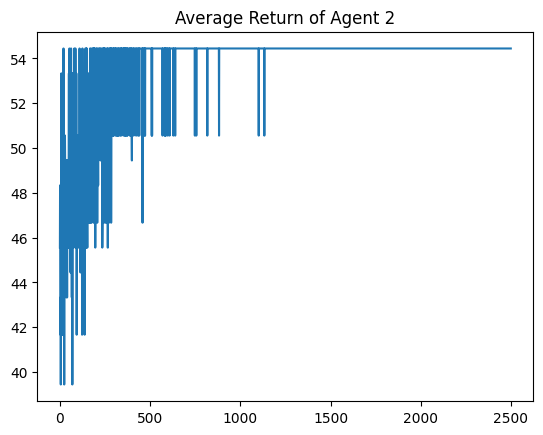

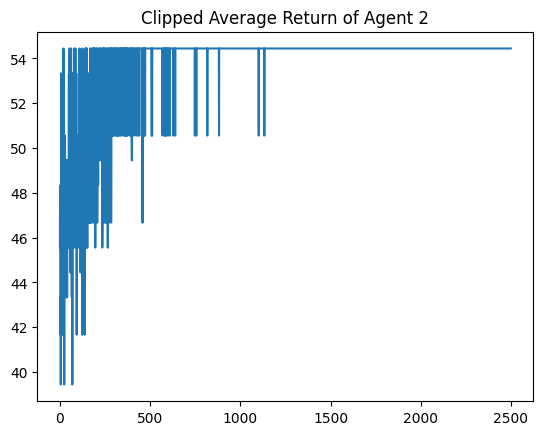

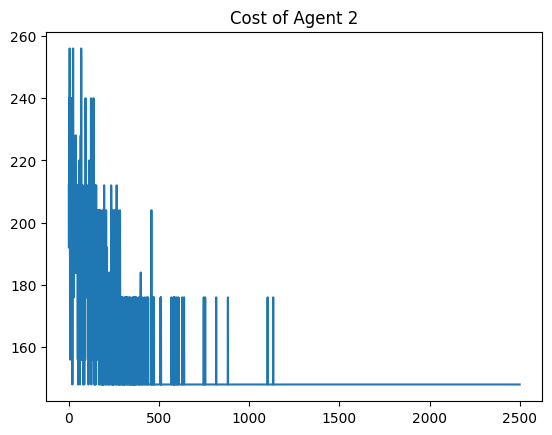

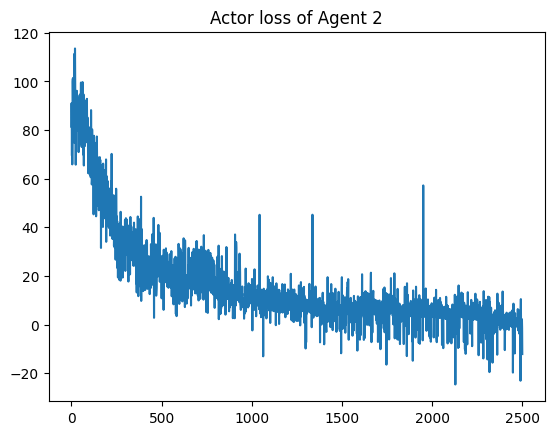

In [25]:
import matplotlib.pyplot as plt
plt.plot(avg_return2)
plt.title("Average Return of Agent 2")
plt.show()

# Define a clipping range
clipped_data2 = np.clip(avg_return2, -500, 500)

# Plot clipped data
plt.plot(clipped_data2)
plt.title("Clipped Average Return of Agent 2")
plt.show()

plt.plot(all_cost2)
plt.title("Cost of Agent 2")
plt.show()

plt.plot(avg_a_loss2)
plt.title("Actor loss of Agent 2")
plt.show()

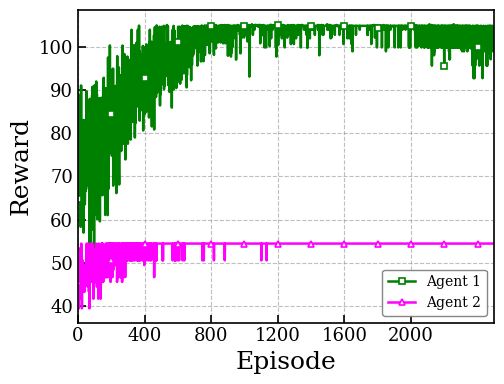

In [26]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------
# IEEE-style plot settings
# -----------------------------------
plt.rcParams.update({
    'font.family': 'DejaVu Serif',
    'font.size': 12,
    'axes.labelsize': 18,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'legend.fontsize': 13,
    'axes.linewidth': 1.2,
    'lines.linewidth': 2.0,
    'grid.linewidth': 0.8,
    'savefig.dpi': 600,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})

# -----------------------------------
# Create figure
# -----------------------------------
fig, ax = plt.subplots(figsize=(5.2, 4.0))

# Plot using your ORIGINAL colors
# Agent 1: Green with circular markers
ax.plot(
    clipped_data1,
    label='Agent 1',
    color='green',
    linestyle='-',
    linewidth=1.8,
    marker='s',
    markersize=4,
    markevery=200,
    markerfacecolor='white',
    markeredgewidth=1.2
)

# Agent 2: Magenta with square markers
ax.plot(
    clipped_data2,
    label='Agent 2',
    color='magenta',
    linestyle='-',
    linewidth=1.8,
    marker='^',
    markersize=4,
    markevery=200,
    markerfacecolor='white',
    markeredgewidth=1.2
)

# -----------------------------------
# Axis labels
# -----------------------------------
ax.set_xlabel('Episode', fontsize=18)
ax.set_ylabel('Reward', fontsize=18)

# -----------------------------------
# Axis limits and ticks
# -----------------------------------
ax.set_xlim(0, max(len(clipped_data1),
                   len(clipped_data2)) - 1)

ax.set_xticks(np.arange(0, 2100, 400))

ax.tick_params(
    axis='both',
    which='major',
    direction='in',
    length=6,
    width=1.2,
    labelsize=13
)

# -----------------------------------
# Grid
# -----------------------------------
ax.grid(
    True,
    which='major',
    linestyle='--',
    linewidth=0.8,
    color='gray',
    alpha=0.5
)

# -----------------------------------
# Legend
# -----------------------------------
ax.legend(
    loc='lower right',
    fontsize=10,
    frameon=True,
    framealpha=0.95,
    edgecolor='gray'
)

# -----------------------------------
# Layout and save
# -----------------------------------
plt.tight_layout()

# plt.savefig(
#     "reward_vs_episode_ha2c_45_lr_0_000001_3000epochs.png",
#     dpi=600,
#     bbox_inches='tight'
# )

plt.show()

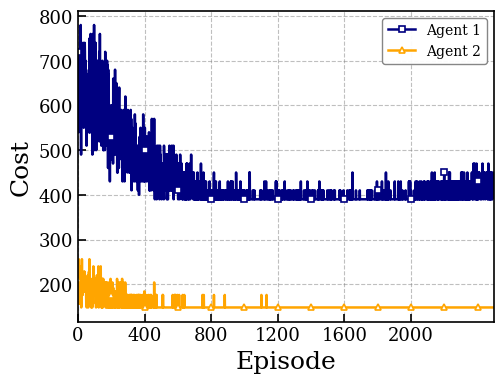

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------
# IEEE-style plot settings
# -----------------------------------
plt.rcParams.update({
    'font.family': 'DejaVu Serif',
    'font.size': 12,
    'axes.labelsize': 18,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'legend.fontsize': 13,
    'axes.linewidth': 1.2,
    'lines.linewidth': 2.0,
    'grid.linewidth': 0.8,
    'savefig.dpi': 600,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})

# -----------------------------------
# Create figure
# -----------------------------------
fig, ax = plt.subplots(figsize=(5.2, 4.0))

# Plot using your ORIGINAL colors
# Agent 1: Green with circular markers
ax.plot(
    all_cost1,
    label='Agent 1',
    color='navy',
    linestyle='-',
    linewidth=1.8,
    marker='s',
    markersize=4,
    markevery=200,
    markerfacecolor='white',
    markeredgewidth=1.2
)

# Agent 2: Magenta with square markers
ax.plot(
    all_cost2,
    label='Agent 2',
    color='orange',
    linestyle='-',
    linewidth=1.8,
    marker='^',
    markersize=4,
    markevery=200,
    markerfacecolor='white',
    markeredgewidth=1.2
)

# -----------------------------------
# Axis labels
# -----------------------------------
ax.set_xlabel('Episode', fontsize=18)
ax.set_ylabel('Cost', fontsize=18)

# -----------------------------------
# Axis limits and ticks
# -----------------------------------
ax.set_xlim(0, max(len(all_cost1),
                   len(all_cost2)) - 1)

ax.set_xticks(np.arange(0, 2100, 400))

ax.tick_params(
    axis='both',
    which='major',
    direction='in',
    length=6,
    width=1.2,
    labelsize=13
)

# -----------------------------------
# Grid
# -----------------------------------
ax.grid(
    True,
    which='major',
    linestyle='--',
    linewidth=0.8,
    color='gray',
    alpha=0.5
)

# -----------------------------------
# Legend
# -----------------------------------
ax.legend(
    loc='upper right',
    fontsize=10,
    frameon=True,
    framealpha=0.95,
    edgecolor='gray'
)

# -----------------------------------
# Layout and save
# -----------------------------------
plt.tight_layout()

# plt.savefig(
#     "cost_vs_episode_ha2c_45_lr_0_000001_3000epochs.png",
#     dpi=600,
#     bbox_inches='tight'
# )

plt.show()

In [28]:
import numpy as np


# ============================================================
# SAVE 2: TRAINING HISTORIES + FINAL PLACEMENT DECISIONS
# Run after both agents complete and g1_to_g2 is constructed.
# ============================================================

g1_to_g2_array = np.asarray(
    sorted(g1_to_g2.items()),
    dtype=np.int64
).reshape(-1, 2)

e2_to_g1_array = np.asarray(
    sorted(e2_to_g1.items()),
    dtype=np.int64
).reshape(-1, 2)


np.savez_compressed(
    "ha2c_training_results_45 nodes_lr_0_000001.npz",

    # Agent 1 training histories
    agent1_cost=np.asarray(all_cost1, dtype=np.float64),
    agent1_reward=np.asarray(avg_return1, dtype=np.float64),
    agent1_actor_loss_lr_0_000001=np.asarray(avg_a_loss1, dtype=np.float64),
    agent1_critic_loss=np.asarray(avg_c_loss1, dtype=np.float64),

    # Agent 2 training histories
    agent2_cost=np.asarray(all_cost2, dtype=np.float64),
    agent2_reward=np.asarray(avg_return2, dtype=np.float64),
    agent2_actor_loss_lr_0_000001=np.asarray(avg_a_loss2, dtype=np.float64),
    agent2_critic_loss=np.asarray(avg_c_loss2, dtype=np.float64),

    # Final placement decisions
    agent1_selected_nodes=np.asarray(
        selected_nodes1, dtype=np.int64
    ),

    agent2_selected_nodes=np.asarray(
        selected_nodes2, dtype=np.int64
    ),

    # Final E2-to-G1 and G1-to-G2 associations
    e2_to_g1_association=e2_to_g1_array,
    g1_to_g2_association=g1_to_g2_array,

    # Final E2 node and active G1 node IDs
    e2_nodes=np.asarray(edge_nodes, dtype=np.int64),
    active_g1_nodes=np.asarray(active_g1_nodes, dtype=np.int64),

    # Original topology latency matrix
    latency_matrix=np.asarray(latency, dtype=np.float64),
)

print("Saved: ha2c_training_results_45 nodes_lr_0_000001.npz")

import torch

# ============================================================
# SAVE V8 TRAINED MODELS AND OPTIMIZER STATES
# ============================================================

torch.save(
    {
        # Agent 1: Actor and Critic
        "actor1_state_dict": actor1.state_dict(),
        "critic1_state_dict": critic1.state_dict(),

        # Agent 2: Actor and Critic
        "actor2_state_dict": actor2.state_dict(),
        "critic2_state_dict": critic2.state_dict(),

        # Agent 1: Optimizers
        "optimizerA1_state_dict": optimizerA1.state_dict(),
        "optimizerC1_state_dict": optimizerC1.state_dict(),

        # Agent 2: Optimizers
        "optimizerA2_state_dict": optimizerA2.state_dict(),
        "optimizerC2_state_dict": optimizerC2.state_dict(),

        # Training configuration
        "gamma": gamma,
        "total_episodes_agent1": len(avg_return1),
        "total_episodes_agent2": len(avg_return2),
    },
    "ha2c_trained_models_45_nodes_lr_0_000001.pt"
)

print("Saved: ha2c_trained_models_45_nodes_lr_0_000001.pt")

Saved: ha2c_training_results_45 nodes_lr_0_000001.npz
Saved: ha2c_trained_models_45_nodes_lr_0_000001.pt
